# 05. Gradient boosting, tuning, monotonic constraints and validation

Boosting fits trees in sequence, each one to the gradient of the loss left by the ensemble so far,
shrunk by a learning rate. XGBoost, LightGBM and CatBoost differ in how they grow trees and handle
categorical features; all are compared here against the forest, a single tree and a logistic baseline,
under the same spatial folds.

In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from river_health import modeling as M
t = M.prepare(pd.read_parquet(ROOT / "data" / "processed" / "river_features.parquet"))

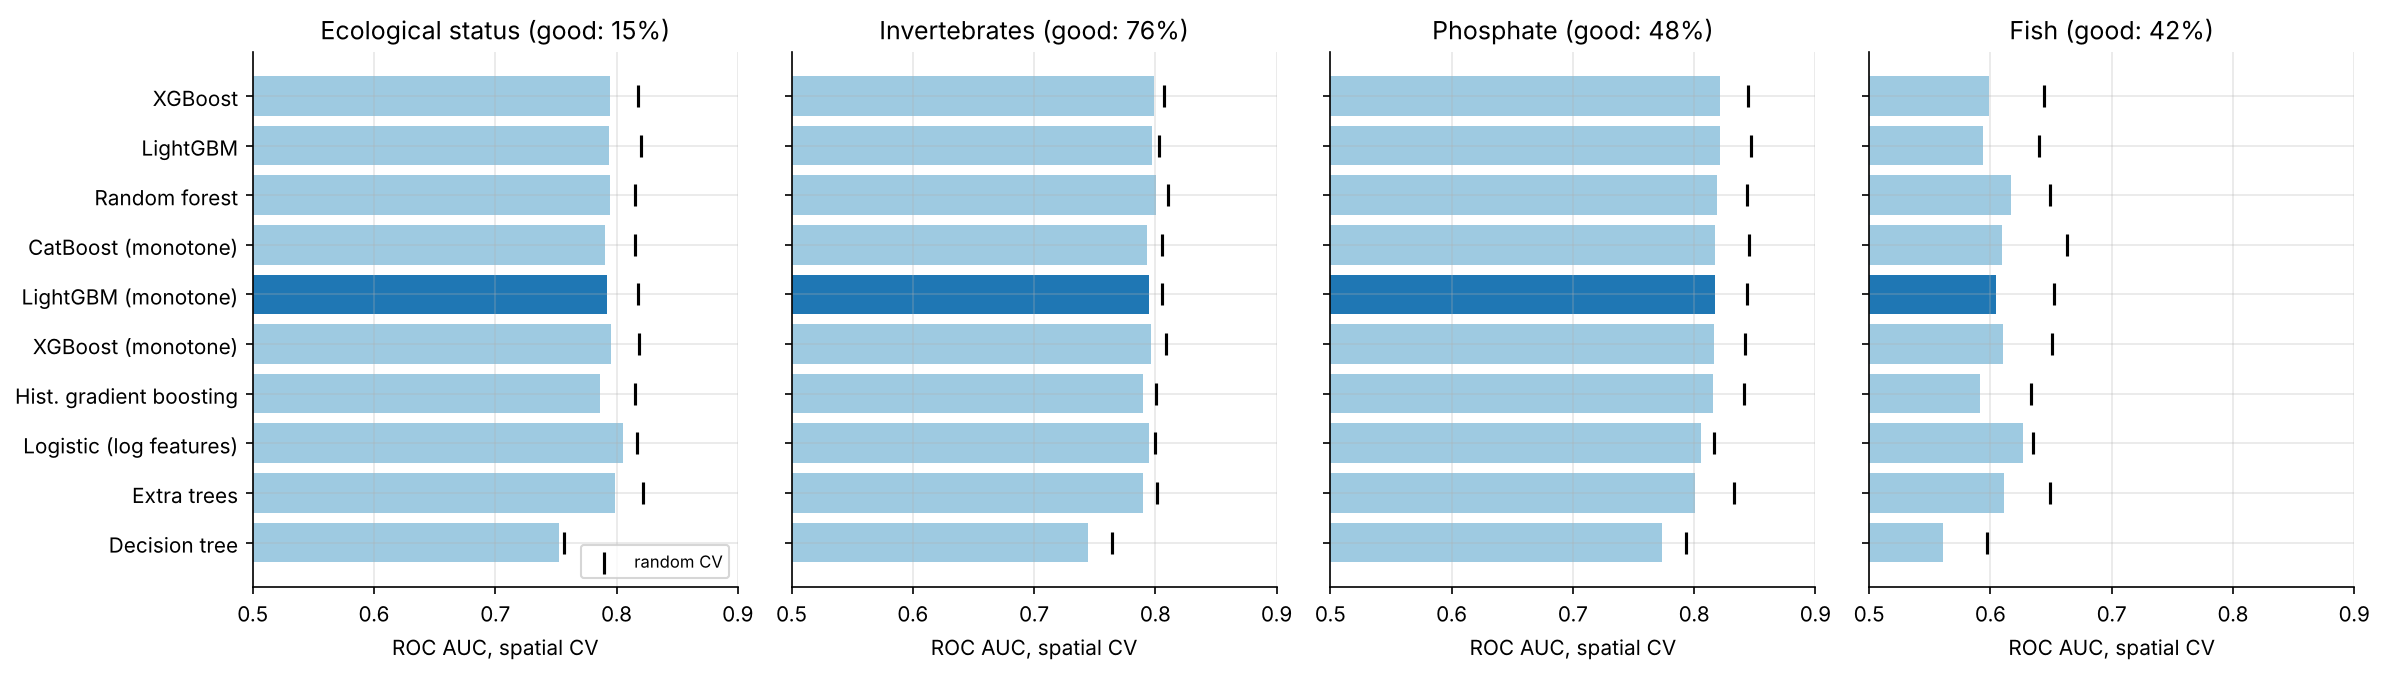

In [2]:
display(Image(FIG / "benchmark_auc.png"))

In [3]:
b = pd.read_csv(T / "benchmark.csv")
sp = b[(b.features == "pressures") & (b.cv == "spatial")]
sp.assign(model=sp.model + np.where(sp.monotone, " (monotone)", "")).pivot(
    index="model", columns="target", values="roc_auc").round(3).sort_values("phos_good", ascending=False)

target,eco_good,fish_good,inv_good,phos_good
model,,,,
xgboost,0.794,0.599,0.798,0.822
lightgbm,0.793,0.594,0.798,0.821
random_forest,0.794,0.617,0.800,0.818
catboost (monotone),0.790,0.610,0.794,0.818
xgboost (monotone),0.796,0.611,0.796,0.817
lightgbm (monotone),0.792,0.605,0.795,0.817
hist_gb,0.786,0.591,0.790,0.816
logistic,0.805,0.626,0.795,0.806
extra_trees,0.799,0.611,0.790,0.801


* The ensembles beat one tree by 0.04-0.05 AUC on every target.
* **A logistic regression on log-transformed pressures is nearly as good** for overall status and for
  invertebrates. These relationships are close to monotone and additive on the log scale, so trees add
  little. Boosting earns its keep on **phosphate**, where dilution makes the effect of effluent depend on
  catchment size and geology.
* Fish status is barely predictable (AUC about 0.6) from these pressures.

## Random folds flatter flexible models most

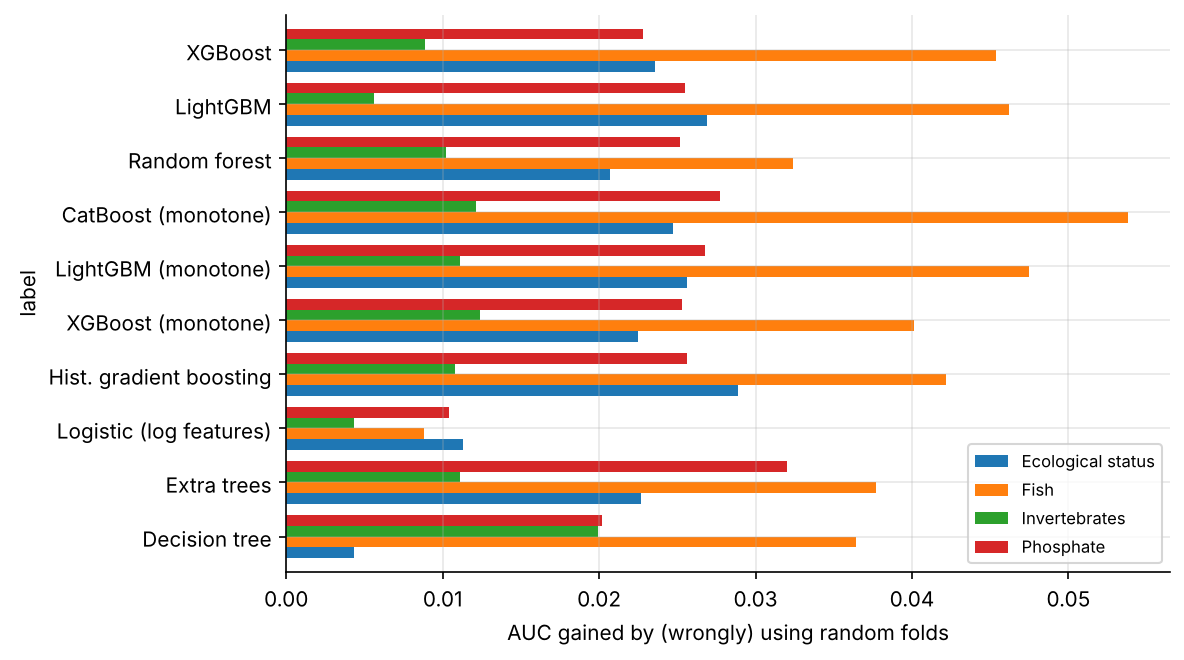

In [4]:
display(Image(FIG / "cv_optimism.png"))

Neighbouring water bodies share geology, land use and often the same sewage works. With random folds a
flexible model can recognise a place rather than learn a relationship; the gap between random and
spatial CV is largest for the most flexible models.

## Nested tuning with Optuna

In [5]:
n = pd.read_csv(T / "nested_tuning.csv")
print(n[n.fold == "all"][["target", "test_auc", "log_loss"]].round(3).to_string(index=False))
n[n.fold != "all"].groupby("target")[[c for c in n.columns if c.startswith("p_")]].median().round(3)

   target  test_auc  log_loss
 eco_good     0.801     0.346
 inv_good     0.798     0.436
phos_good     0.812     0.520


,p_n_estimators,p_learning_rate,p_num_leaves,p_min_child_samples,p_subsample,p_colsample_bytree,p_reg_lambda
target,,,,,,,
eco_good,200.0,0.012,6.0,67.0,0.769,0.578,2.660
inv_good,200.0,0.017,9.0,27.0,0.549,0.706,0.026
phos_good,400.0,0.014,10.0,31.0,0.676,0.564,0.003


Each outer fold is tuned on its own training catchments (inner 4-fold spatial CV, 30 Optuna trials,
minimising log loss), then scored on its held-out catchments, so the tuned score is honest. The per-fold
searches mostly choose **few leaves (median 6-10), large minimum leaves and strong row subsampling**. The final
all-data searches allow more leaves for overall status and phosphate (42-46), but pair them with a learning rate
of about 0.01 and subsampling. That is heavy regularisation either way, as expected with 3,700 rows. Nested
tuned AUCs (0.80, 0.80, 0.81) match the untuned defaults: tuning gains are small relative to the choice of
features and folds.

In [6]:
json.loads((T / "best_params.json").read_text())

{'eco_good': {'n_estimators': 450,
  'learning_rate': 0.010365111825465886,
  'num_leaves': 42,
  'min_child_samples': 25,
  'subsample': 0.6601717776447111,
  'colsample_bytree': 0.3935362910953001,
  'reg_lambda': 12.313577251618778},
 'inv_good': {'n_estimators': 400,
  'learning_rate': 0.011154105948642122,
  'num_leaves': 9,
  'min_child_samples': 13,
  'subsample': 0.540059121415949,
  'colsample_bytree': 0.7683900858646981,
  'reg_lambda': 3.543940439820089},
 'phos_good': {'n_estimators': 300,
  'learning_rate': 0.011070522896791076,
  'num_leaves': 46,
  'min_child_samples': 28,
  'subsample': 0.5143893181775568,
  'colsample_bytree': 0.790556956578515,
  'reg_lambda': 1.4132380114215217}}

## Monotonic constraints

In [7]:
mono = b[(b.features == "pressures") & (b.cv == "spatial") & b.model.isin(["lightgbm", "xgboost"])]
mono.pivot_table(index=["model", "monotone"], columns="target", values="roc_auc").round(3)

target             eco_good  fish_good  inv_good  phos_good
model    monotone                                          
lightgbm False        0.793      0.594     0.798      0.821
         True         0.792      0.605     0.795      0.817
xgboost  False        0.794      0.599     0.798      0.822
         True         0.796      0.611     0.796      0.817

Constraining the model so that more spills, more sewage effluent or more urban land can **never raise**
the predicted chance of good status costs about 0.003 AUC. In exchange every scenario in notebook 07
is guaranteed to move in the physically sensible direction, and odd wiggles in the fitted curves
(noise fitted as signal) disappear.

## Calibration

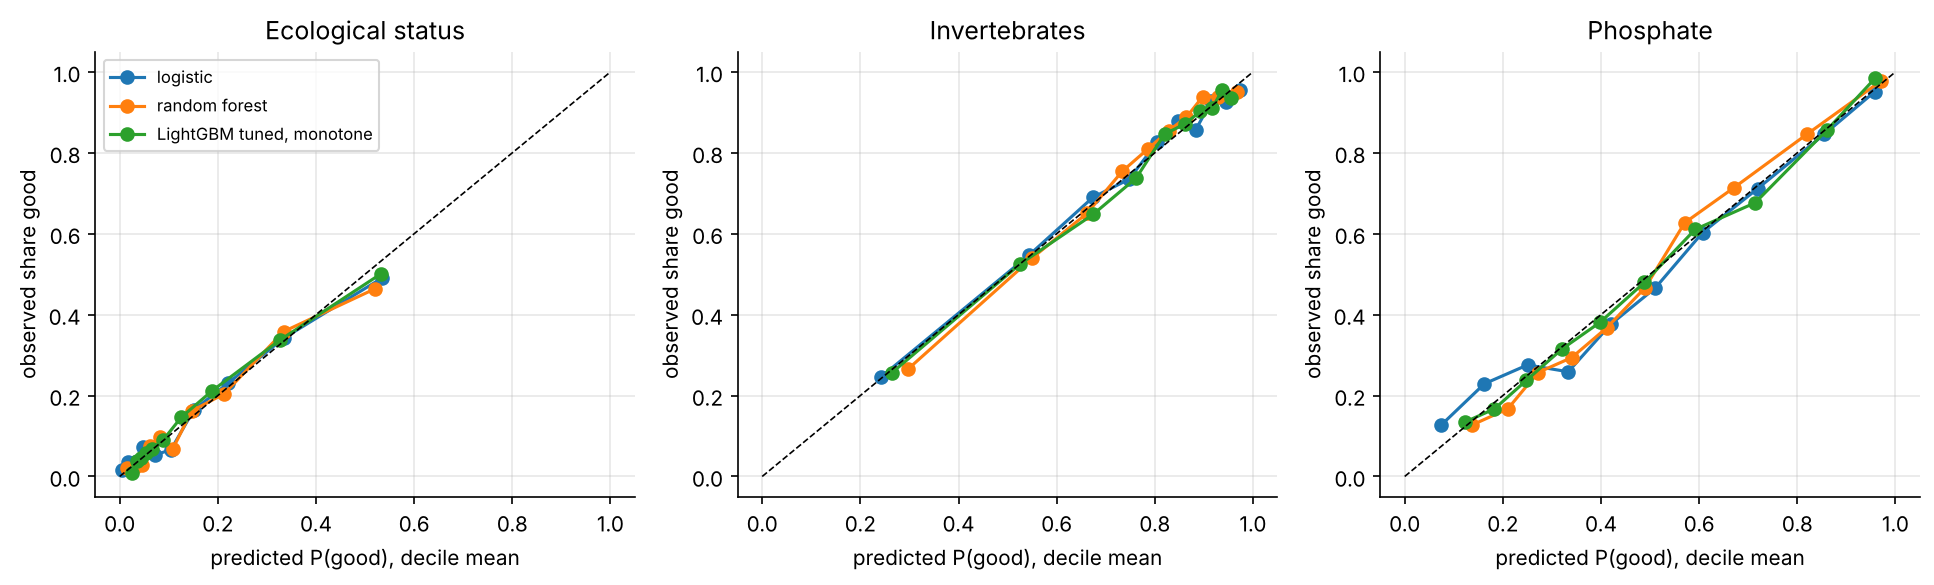

,target,model,roc_auc,pr_auc,log_loss,brier,base_rate
0,eco_good,logistic,0.805,0.414,0.344,0.105,0.150
1,eco_good,random_forest,0.794,0.381,0.350,0.108,0.150
2,eco_good,lightgbm_tuned_mono,0.803,0.410,0.344,0.106,0.150
3,inv_good,logistic,0.795,0.910,0.438,0.138,0.759
4,inv_good,random_forest,0.800,0.909,0.438,0.138,0.759
5,inv_good,lightgbm_tuned_mono,0.804,0.909,0.431,0.136,0.759
6,phos_good,logistic,0.806,0.816,0.532,0.179,0.484
7,phos_good,random_forest,0.818,0.829,0.516,0.173,0.484
8,phos_good,lightgbm_tuned_mono,0.817,0.830,0.514,0.172,0.484


In [8]:
display(Image(FIG / "calibration.png"))
pd.read_csv(T / "champions.csv").round(3)

## Chemistry: what is missing from the pressures

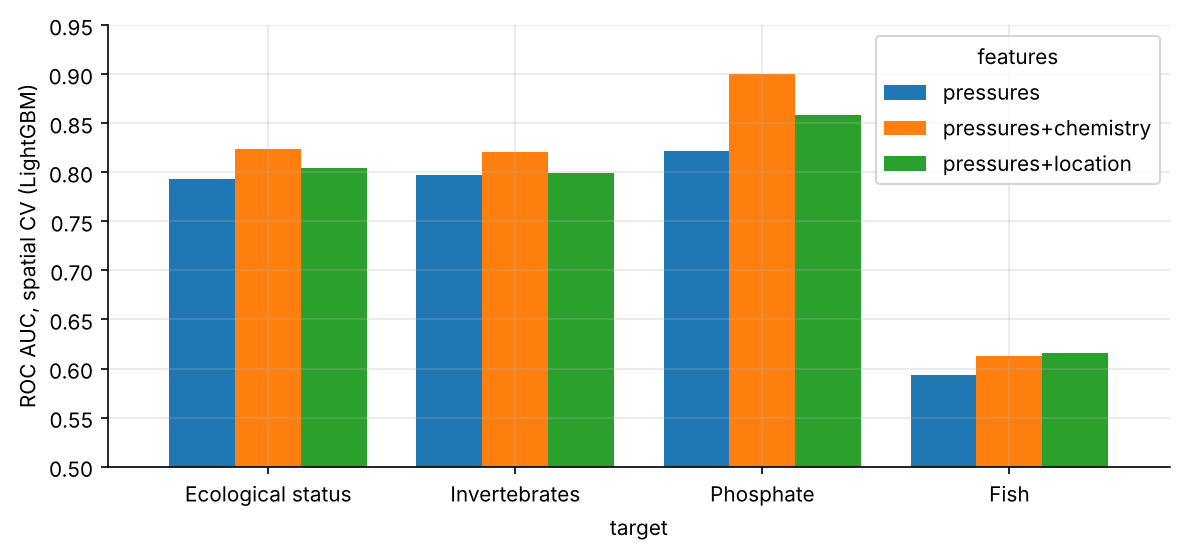

In [9]:
display(Image(FIG / "feature_sets.png"))

Adding measured chemistry lifts phosphate AUC from about 0.82 to 0.90, partly by construction (the
phosphate class *is* a concentration threshold). Adding only the coordinates lifts it by about 0.03:
there is spatial structure the pressures do not explain (soils, rainfall, livestock density, phosphorus
removal at individual works). Those are the next data to add.

## The ordinal target: invertebrate class from bad (0) to high (4)

,model,qwk,qwk_expected,accuracy,mae_expected,log_loss
0,multiclass,0.414,0.407,0.479,0.669,1.210
1,frank_hall_monotone,0.439,0.434,0.481,0.668,1.228
2,prior_only,0.000,0.000,0.426,0.780,1.272


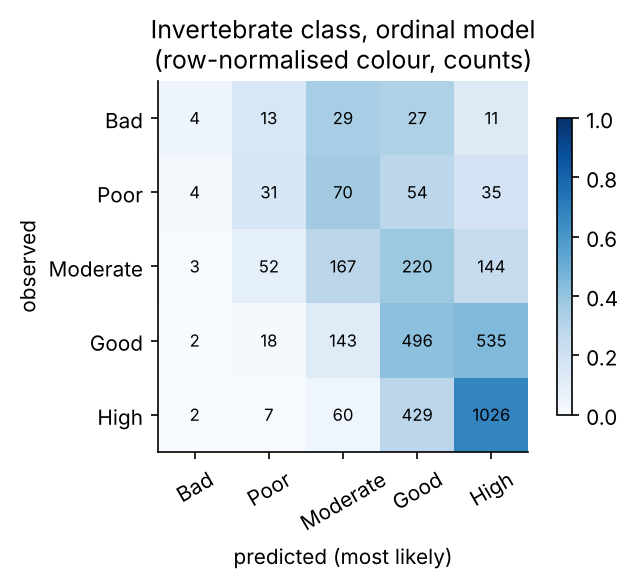

In [10]:
display(pd.read_csv(T / "ordinal_inv_class.csv").round(3))
display(Image(FIG / "ordinal_confusion.png"))

The Frank & Hall decomposition fits four monotone binary models, P(class > k) for k = 0..3, and turns
them into class probabilities. It respects the ordering that a plain multiclass model ignores, and it scores
better on quadratic weighted kappa (0.44 vs 0.41), which penalises a bad-as-high mistake more than a
good-as-high one. Its log loss is slightly worse (1.23 vs 1.21): ordering helps rank the classes, not sharpen
the probabilities.